# ADSP 31014 – Statistical Models for Data Science
## Homework 6

**Name:** Obaro Erigha
**Term:** Autumn 2026

In [13]:
library(dplyr)
library(ggplot2)

data <- read.csv('../../Week3/Hw3/chicago_taxi_trip_sample.csv')
dim(data)

[1] 100000     17

#### Question 1a. Linear Regression with glm():

In [2]:
model.1a <- glm(trip_seconds ~ fare + trip_miles + tips_percent,
                family = gaussian, data = data)
summary(model.1a)


Call:
glm(formula = trip_seconds ~ fare + trip_miles + tips_percent, 
    family = gaussian, data = data)

Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept)   153.9834     3.1951   48.19   <2e-16 ***
fare           53.3593     0.2523  211.49   <2e-16 ***
trip_miles     -9.3389     0.5915  -15.79   <2e-16 ***
tips_percent -112.9620     9.0675  -12.46   <2e-16 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for gaussian family taken to be 261646.2)

    Null deviance: 8.1913e+10  on 99999  degrees of freedom
Residual deviance: 2.6164e+10  on 99996  degrees of freedom
AIC: 1531269

Number of Fisher Scoring iterations: 2


Fitted model: trip_seconds = 153.9834 + 53.3593 fare - 9.3389 trip_miles - 112.9620 tips_percent

The dispersion parameter 261646.2 is the estimated error variance sigma^2. Residual deviance = 2.6164e+10 on 99996 degrees of freedom. AIC = 1531269.

#### Question 1b. Same Model with lm():

In [3]:
model.1b <- lm(trip_seconds ~ fare + trip_miles + tips_percent, data = data)
summary(model.1b)

# Coefficient tables and fitted values from both functions
all.equal(coef(summary(model.1a)), coef(summary(model.1b)))
all.equal(fitted(model.1a), fitted(model.1b))


Call:
lm(formula = trip_seconds ~ fare + trip_miles + tips_percent, 
    data = data)

Residuals:
    Min      1Q  Median      3Q     Max 
-8115.6  -207.1   -49.6   146.4  6329.4 

Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept)   153.9834     3.1951   48.19   <2e-16 ***
fare           53.3593     0.2523  211.49   <2e-16 ***
trip_miles     -9.3389     0.5915  -15.79   <2e-16 ***
tips_percent -112.9620     9.0675  -12.46   <2e-16 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Residual standard error: 511.5 on 99996 degrees of freedom
Multiple R-squared:  0.6806,	Adjusted R-squared:  0.6806 
F-statistic: 7.102e+04 on 3 and 99996 DF,  p-value: < 2.2e-16


[1] TRUE

[1] TRUE

Both functions give the same fitted model: identical estimates, standard errors, t values and p-values, and identical fitted values.

The residual standard error from lm() is 511.5, and 511.5^2 = 261646, which matches the dispersion parameter reported by glm(). glm() fits by iteratively reweighted least squares, but for the gaussian family with the identity link that is just ordinary least squares, so it gets there in one step (the second Fisher scoring iteration only confirms convergence).

#### Question 1c. Residual Deviance vs Sum of Squared Residuals:

In [4]:
options(digits = 12)
deviance(model.1a)          # residual deviance of the glm() model
sum(residuals(model.1b)^2)  # sum of squared residuals of the lm() model
all.equal(deviance(model.1a), sum(residuals(model.1b)^2))
options(digits = 7)

[1] 26163571297.2

[1] 26163571297.2

[1] TRUE

Residual deviance = sum of squared residuals = 26,163,571,297 (rounded). For the gaussian family the deviance is defined as the sum of squared residuals, so the two are the same.

#### Question 2a. Downtown to Airport by Hour:

In [5]:
downtown <- data[data['pickup_area'] == 'Downtown',]
downtown$to_airport <- downtown$dropoff_area %in% c('Midway', 'O\'Hare')
nrow(downtown)

airport.by.hour <- downtown %>%
  group_by(hour) %>%
  summarise(trips = n(), airport.trips = sum(to_airport), fraction = mean(to_airport))
as.data.frame(airport.by.hour)

airport.by.hour[which.max(airport.by.hour$fraction), ]

[1] 48862

hour,trips,airport.trips,fraction
<int>,<int>,<int>,<dbl>
0,654,4,0.006116208
1,447,2,0.004474273
2,307,9,0.029315961
3,253,56,0.221343874
4,279,126,0.451612903
5,373,215,0.576407507
6,766,324,0.422976501
7,1512,339,0.224206349
8,2500,262,0.104800000


hour,trips,airport.trips,fraction
<int>,<int>,<int>,<dbl>
5,373,215,0.5764075


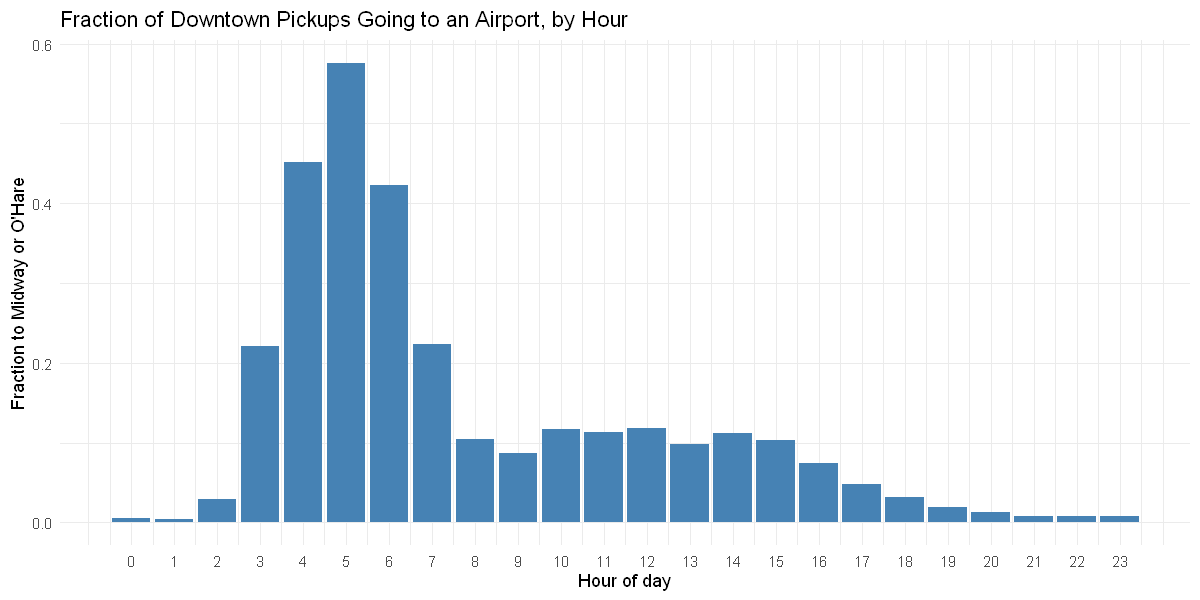

In [6]:
options(repr.plot.width = 10, repr.plot.height = 5)
ggplot(airport.by.hour, aes(x = hour, y = fraction)) +
  geom_col(fill = 'steelblue') +
  scale_x_continuous(breaks = 0:23) +
  labs(title = 'Fraction of Downtown Pickups Going to an Airport, by Hour',
       x = 'Hour of day', y = 'Fraction to Midway or O\'Hare') +
  theme_minimal()

There are 48,862 trips with downtown departure.

Hour 5 (5 AM) has the highest fraction of trips to the airport: 215 of 373 trips, a fraction of 0.5764.

The fraction rises sharply from 3 AM, peaks at 5 AM and is still high at 6 AM, then drops to around 0.10 during the working day. It falls below 0.02 from 7 PM to 2 AM. Early morning downtown trips are mostly people heading to catch flights.

#### Question 2b. Logistic Regression on Hour:

In [7]:
model.2b <- glm(to_airport ~ factor(hour) - 1, family = binomial, data = downtown)
summary(model.2b)


Call:
glm(formula = to_airport ~ factor(hour) - 1, family = binomial, 
    data = downtown)

Coefficients:
               Estimate Std. Error z value Pr(>|z|)    
factor(hour)0  -5.09068    0.50141 -10.153  < 2e-16 ***
factor(hour)1  -5.40492    0.70776  -7.637 2.23e-14 ***
factor(hour)2  -3.49987    0.33833 -10.345  < 2e-16 ***
factor(hour)3  -1.25785    0.15144  -8.306  < 2e-16 ***
factor(hour)4  -0.19416    0.12030  -1.614  0.10655    
factor(hour)5   0.30804    0.10479   2.940  0.00329 ** 
factor(hour)6  -0.31057    0.07314  -4.246 2.17e-05 ***
factor(hour)7  -1.24132    0.06166 -20.131  < 2e-16 ***
factor(hour)8  -2.14499    0.06530 -32.850  < 2e-16 ***
factor(hour)9  -2.34898    0.07073 -33.213  < 2e-16 ***
factor(hour)10 -2.01825    0.05969 -33.814  < 2e-16 ***
factor(hour)11 -2.05521    0.05856 -35.098  < 2e-16 ***
factor(hour)12 -2.01214    0.05589 -36.005  < 2e-16 ***
factor(hour)13 -2.21700    0.06020 -36.828  < 2e-16 ***
factor(hour)14 -2.06282    0.05565 -37.071  < 2e-16 

With the -1 the model has no intercept, so there is one coefficient per hour and no reference hour. Each coefficient is directly the log-odds of going to the airport for that hour, and its z-test checks whether that hour's log-odds is 0 (a probability of 0.5).

Without the -1, hour 0 would be absorbed into the intercept and every other coefficient would be a difference in log-odds relative to hour 0. To read off any one hour we would have to add the intercept to its coefficient, and the z-tests would compare each hour to hour 0 instead.

For example, hour 5 is the only positive coefficient (0.30804), so it is the only hour where an airport trip is more likely than not. Hour 4 (-0.19416, p-value = 0.10655) is the only hour whose probability is not significantly different from 0.5.

#### Question 2c. Predicted Probabilities from the Coefficients:

In [8]:
beta <- coef(model.2b)
predicted <- data.frame(hour = 0:23,
                        log.odds = beta,
                        probability = exp(beta) / (1 + exp(beta)),
                        row.names = NULL)
predicted

hour,log.odds,probability
<int>,<dbl>,<dbl>
0,-5.0906779,0.006116209
1,-5.4049236,0.004474289
2,-3.4998689,0.029315961
3,-1.2578520,0.221343874
4,-0.1941560,0.451612903
5,0.3080430,0.576407507
6,-0.3105664,0.422976501
7,-1.2413197,0.224206349
8,-2.1449934,0.104800000


The predicted probability for each hour is the inverse logit of its coefficient, p = exp(beta) / (1 + exp(beta)). The highest is hour 5 with 0.5764 and the lowest is hour 1 with 0.0045.

#### Question 2d. Predicted Probabilities vs Fractions:

In [9]:
comparison <- data.frame(hour = airport.by.hour$hour,
                         fraction = airport.by.hour$fraction,
                         probability = predicted$probability)
comparison
max(abs(comparison$fraction - comparison$probability))

hour,fraction,probability
<int>,<dbl>,<dbl>
0,0.006116208,0.006116209
1,0.004474273,0.004474289
2,0.029315961,0.029315961
3,0.221343874,0.221343874
4,0.451612903,0.451612903
5,0.576407507,0.576407507
6,0.422976501,0.422976501
7,0.224206349,0.224206349
8,0.104800000,0.104800000


[1] 1.574579e-08

They are the same. The predicted probability for each hour equals the observed fraction of trips to the airport for that hour (the largest difference is about 1.6e-08, which is just the convergence tolerance of the fitting algorithm).

The model has one free parameter for each hour, so it is saturated with respect to hour. The maximum likelihood estimate of a Bernoulli probability within a group is that group's sample proportion, so the logistic regression just reproduces the 24 fractions from 2a on the log-odds scale.

#### Question 2e. Hour and Day of Week, Highest Probability:

In [10]:
model.2e <- glm(to_airport ~ factor(hour) + factor(day_of_week),
                family = binomial, data = downtown)
summary(model.2e)


Call:
glm(formula = to_airport ~ factor(hour) + factor(day_of_week), 
    family = binomial, data = downtown)

Coefficients:
                     Estimate Std. Error z value Pr(>|z|)    
(Intercept)          -5.29509    0.50407 -10.505  < 2e-16 ***
factor(hour)1        -0.33359    0.86755  -0.385 0.700597    
factor(hour)2         1.59737    0.60535   2.639 0.008321 ** 
factor(hour)3         3.83067    0.52436   7.305 2.76e-13 ***
factor(hour)4         4.91158    0.51617   9.515  < 2e-16 ***
factor(hour)5         5.49344    0.51278  10.713  < 2e-16 ***
factor(hour)6         4.89509    0.50723   9.651  < 2e-16 ***
factor(hour)7         3.99321    0.50574   7.896 2.88e-15 ***
factor(hour)8         3.10392    0.50621   6.132 8.69e-10 ***
factor(hour)9         2.88167    0.50684   5.686 1.30e-08 ***
factor(hour)10        3.19598    0.50536   6.324 2.55e-10 ***
factor(hour)11        3.15337    0.50522   6.242 4.33e-10 ***
factor(hour)12        3.18987    0.50490   6.318 2.65e-10 ***
factor

In [11]:
grid <- expand.grid(hour = 0:23, day_of_week = 0:6)
grid$probability <- predict(model.2e, newdata = grid, type = 'response')

grid[which.max(grid$probability), ]

,hour,day_of_week,probability
,<int>,<int>,<dbl>
150,5,6,0.6974289


From the summary, hour 5 has the largest hour coefficient (5.49344) and day_of_week 6 has the largest day coefficient (0.63673, relative to Monday = 0). Since the model is additive on the log-odds scale, the highest combination is hour 5 on day_of_week 6 (Sunday).

Predicted probability = 0.6974 (5 AM on Sunday).

#### Question 2f. Lowest Probability:

In [12]:
grid[which.min(grid$probability), ]

,hour,day_of_week,probability
,<int>,<int>,<dbl>
26,1,1,0.003026572


The lowest combination is hour 1 on day_of_week 1 (Tuesday). Hour 1 has the smallest hour coefficient (-0.33359, relative to hour 0) and day_of_week 1 has the smallest day coefficient (-0.16862, relative to Monday).

Predicted probability = 0.003027 (1 AM on Tuesday).